<a href="https://colab.research.google.com/github/patilvedantp/T170800521_TNSIF_AIML/blob/main/Day_8_(EDA).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 🎯 Objective
In this step, we will:
- Setup Kaggle API
- Download dataset from Kaggle
- Load dataset into Pandas DataFrame

In [ ]:
from google.colab import files

uploaded = files.upload()  # Select kaggle.json from your computer

Saving kaggle.json to kaggle.json


## ⚙️ Configure Kaggle API

In [ ]:
import os
import shutil

# Create Kaggle directory
os.makedirs('/root/.kaggle', exist_ok=True)

# Move uploaded file
shutil.move('kaggle.json', '/root/.kaggle/kaggle.json')

# Set permissions
os.chmod('/root/.kaggle/kaggle.json', 600)

## 📥 Download Dataset from Kaggle

Dataset: Simple Rainfall Classification Dataset

In [ ]:
!pip install -q kaggle

In [ ]:
!kaggle datasets download -d sujithmandala/simple-rainfall-classification-dataset

Dataset URL: https://www.kaggle.com/datasets/sujithmandala/simple-rainfall-classification-dataset
License(s): CC-BY-SA-4.0
100% 804/804 [00:00<00:00, 2.31MB/s]



## 📦 Extract Dataset

In [ ]:
import zipfile

with zipfile.ZipFile('simple-rainfall-classification-dataset.zip', 'r') as zip_ref:
    zip_ref.extractall('rainfall_dataset')

## 📊 Load Dataset into Pandas

In [ ]:
import os

print(os.listdir('rainfall_dataset'))

['rainfall.csv']


In [ ]:
import pandas as pd

# Replace filename with the actual CSV name printed above
df = pd.read_csv('rainfall_dataset/rainfall.csv')

print(df.head())
print(df.shape)

         date  rainfall  temperature  humidity  wind_speed weather_condition
0  2022-01-01      12.5         15.2      78.0         8.5             Rainy
1  2022-01-02       8.2         17.8      65.0         5.2             Rainy
2  2022-01-03       0.0         20.1      52.0         3.1             Sunny
3  2022-01-04       3.7         18.6      71.0         6.7             Rainy
4  2022-01-05      21.1         14.8      82.0         9.3             Rainy
(54, 6)


## 🔍 Basic Structure Check

In [ ]:
# Shape of dataset
df.shape

# Column names
df.columns

Index(['date', 'rainfall', 'temperature', 'humidity', 'wind_speed',
       'weather_condition'],
      dtype='object')

## 🎯 Objective
In this step, we will:
- Understand dataset structure
- Check data types
- Identify missing values
- Generate statistical summary

## 🔍 View Dataset
Display first and last few records

In [ ]:
# First 5 rows
df.head()

,date,rainfall,temperature,humidity,wind_speed,weather_condition
0,2022-01-01,12.5,15.2,78.0,8.5,Rainy
1,2022-01-02,8.2,17.8,65.0,5.2,Rainy
2,2022-01-03,0.0,20.1,52.0,3.1,Sunny
3,2022-01-04,3.7,18.6,71.0,6.7,Rainy
4,2022-01-05,21.1,14.8,82.0,9.3,Rainy


In [ ]:
# Last 5 rows
df.tail()

,date,rainfall,temperature,humidity,wind_speed,weather_condition
49,2022-02-19,17.3,15.9,83.0,8.6,Rainy
50,2022-02-20,9.6,18.6,71.0,6.7,Rainy
51,2022-02-21,0.0,21.3,55.0,5.1,Sunny
52,2022-02-22,7.4,16.8,77.0,8.9,Rainy
53,Co,NaN,NaN,NaN,NaN,NaN


## 📐 Dataset Shape
Check number of rows and columns

In [ ]:
print("Rows and Columns:", df.shape)

Rows and Columns: (54, 6)


## 🏷 Column Names
List all available features

In [ ]:
print("Columns in dataset:")
print(df.columns)

Columns in dataset:
Index(['date', 'rainfall', 'temperature', 'humidity', 'wind_speed',
       'weather_condition'],
      dtype='object')


## 🔢 Data Types
Understand numeric and categorical columns

In [ ]:
df.dtypes

,0
date,object
rainfall,float64
temperature,float64
humidity,float64
wind_speed,float64
weather_condition,object


## ℹ Dataset Information
Summary of memory usage and non-null values

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   date               54 non-null     object 
 1   rainfall           53 non-null     float64
 2   temperature        53 non-null     float64
 3   humidity           53 non-null     float64
 4   wind_speed         53 non-null     float64
 5   weather_condition  53 non-null     object 
dtypes: float64(4), object(2)
memory usage: 2.7+ KB


## ❓ Missing Values Check
Find null values in each column

In [ ]:
df.isnull().sum()

,0
date,0
rainfall,1
temperature,1
humidity,1
wind_speed,1
weather_condition,1


## 📊 Statistical Summary
Numerical overview of dataset

In [ ]:
df.describe()

,rainfall,temperature,humidity,wind_speed
count,53.000000,53.000000,53.000000,53.000000
mean,9.049057,17.950943,69.245283,6.403774
std,6.712521,2.500663,11.969361,2.209069
min,0.000000,13.900000,44.000000,2.100000
25%,3.900000,16.100000,62.000000,4.700000
50%,8.300000,17.800000,72.000000,6.700000
75%,14.800000,19.400000,78.000000,8.300000
max,21.800000,23.400000,89.000000,10.500000


## 🧠 Initial Observations
While exploring, observe:
- Which columns are numerical
- Which columns are categorical
- Any missing values
- Minimum and maximum values
- Possible outliers

## ✅ Outcome

After this step, we understand:
- Dataset structure
- Data quality
- Feature types
- Summary statistics

#Correlation Analysis

## 🎯 Objective
In this step, we will:
- Understand relationships between numerical features
- Identify strong positive/negative correlations
- Detect multicollinearity

## 📌 What is Correlation?

Correlation measures how strongly two variables are related.

- +1 → Strong positive relationship
- -1 → Strong negative relationship
- 0 → No relationship

## 🔢 Compute Correlation Matrix

In [ ]:
# Compute correlation matrix (only numeric columns)
corr_matrix = df.corr(numeric_only=True)

corr_matrix

,rainfall,temperature,humidity,wind_speed
rainfall,1.000000,-0.790566,0.821357,0.733376
temperature,-0.790566,1.000000,-0.966097,-0.902996
humidity,0.821357,-0.966097,1.000000,0.951643
wind_speed,0.733376,-0.902996,0.951643,1.000000


## 🎨 Visualize Correlation using Heatmap

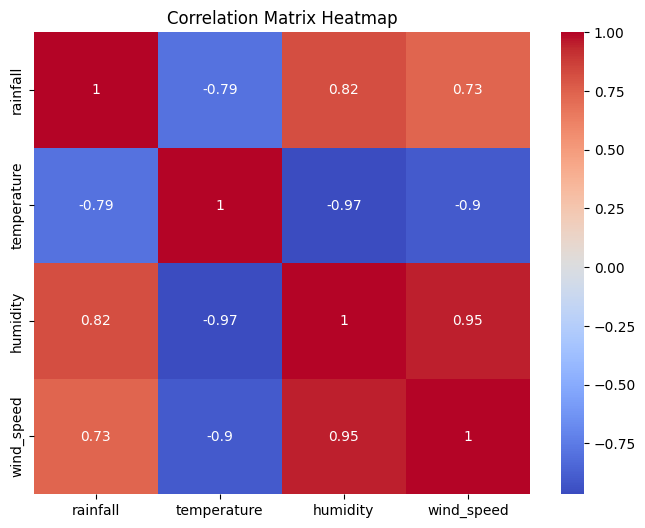

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix Heatmap")
plt.show()

## 🔍 Focus on Target Variable

Check how features relate to the target (e.g., rainfall)

In [ ]:
# Replace 'rainfall' with your target column if different
corr_matrix["rainfall"].sort_values(ascending=False)

,rainfall
rainfall,1.000000
humidity,0.821357
wind_speed,0.733376
temperature,-0.790566


## ⚠️ Detect Multicollinearity

Highly correlated features can affect model performance

In [ ]:
# Find highly correlated feature pairs (> 0.8)
high_corr = []

for i in corr_matrix.columns:
    for j in corr_matrix.columns:
        if i != j and abs(corr_matrix[i][j]) > 0.8:
            high_corr.append((i, j, corr_matrix[i][j]))

high_corr

[('rainfall', 'humidity', np.float64(0.8213569723603099)),
 ('temperature', 'humidity', np.float64(-0.9660971268282758)),
 ('temperature', 'wind_speed', np.float64(-0.9029958088261343)),
 ('humidity', 'rainfall', np.float64(0.8213569723603099)),
 ('humidity', 'temperature', np.float64(-0.9660971268282758)),
 ('humidity', 'wind_speed', np.float64(0.9516425912012718)),
 ('wind_speed', 'temperature', np.float64(-0.9029958088261343)),
 ('wind_speed', 'humidity', np.float64(0.9516425912012718))]

## 🧠 Observations to Make

- Which features strongly affect rainfall?
- Are there strong positive or negative correlations?
- Any redundant features (multicollinearity)?

#Distribution Analysis

## 🎯 Objective
In this step, we will:
- Understand how data is distributed
- Identify skewness (left/right)
- Detect outliers
- Analyze spread of data

## 📌 What is Distribution?

Distribution shows how values of a variable are spread.

We analyze:
- Shape (Normal / Skewed)
- Spread (Variance)
- Outliers

## 📊 Histogram (Distribution of Features)

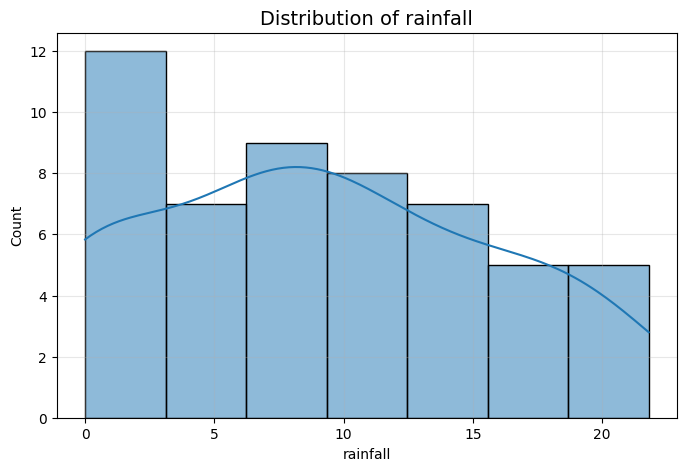

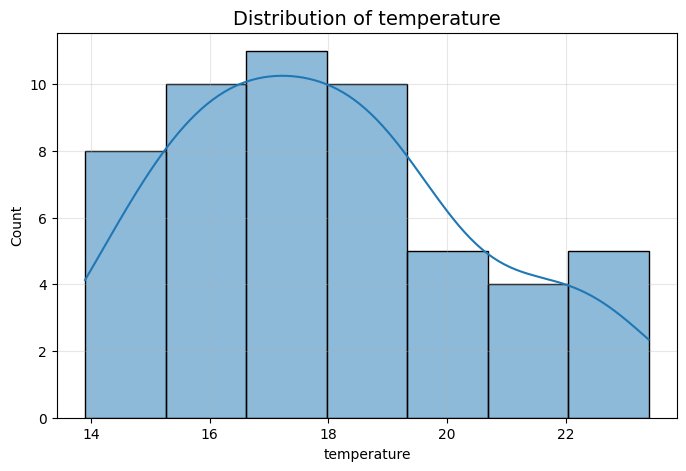

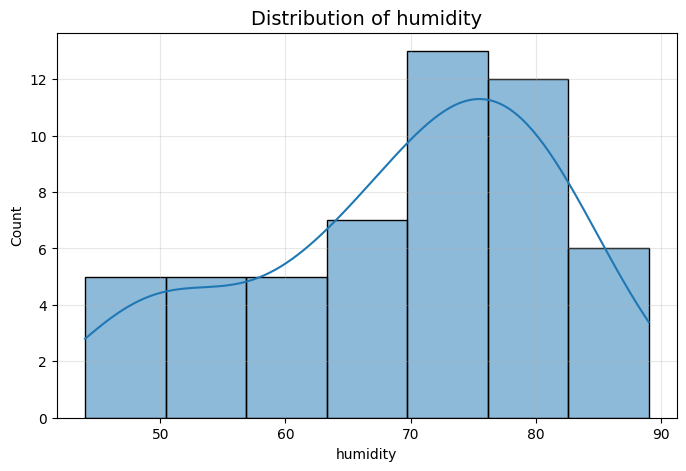

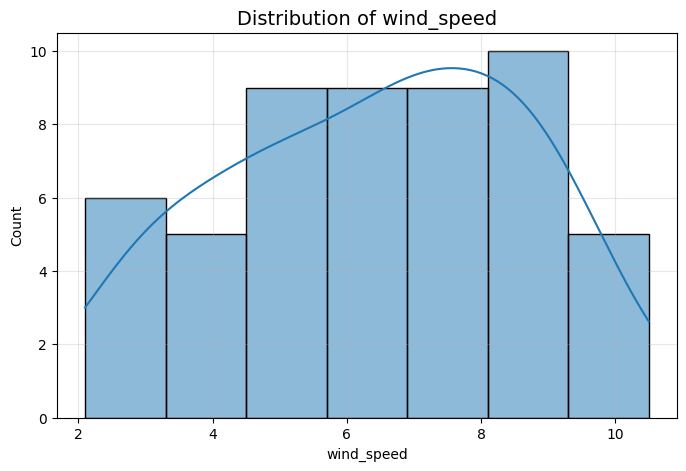

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    plt.figure(figsize=(8,5))

    sns.histplot(
        data=df,
        x=col,
        kde=True
    )

    plt.title(f'Distribution of {col}', fontsize=14)
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.grid(True, alpha=0.3)

    plt.show()

## 🔍 Observations from Histogram

- Is data symmetric?
- Is it skewed (left/right)?
- Are values concentrated or spread out?

## 📦 Boxplot (Outlier Detection)

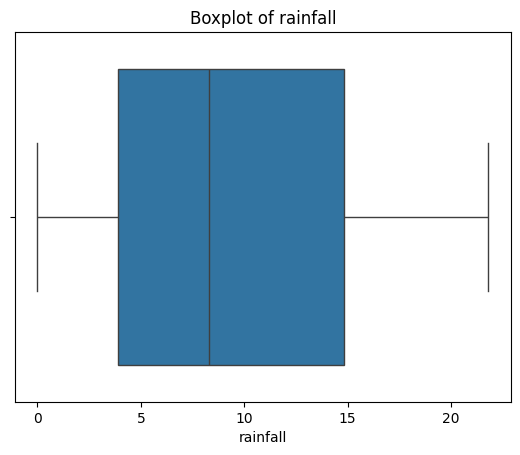

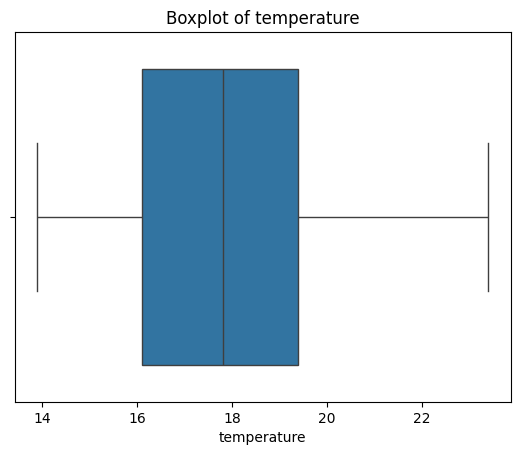

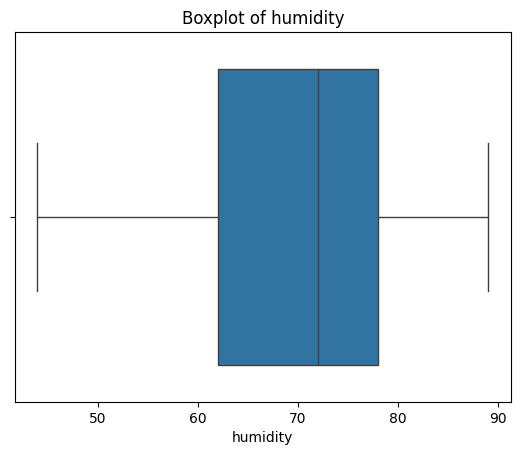

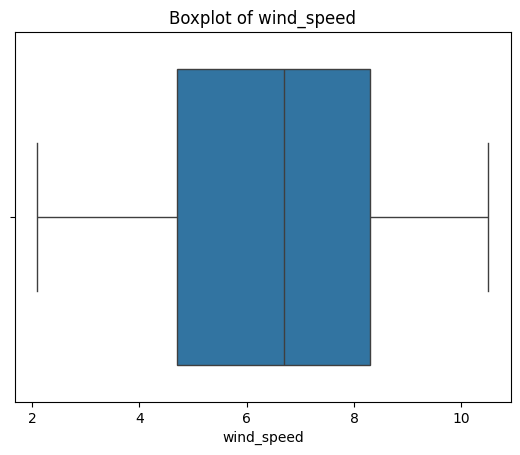

In [ ]:
import seaborn as sns

# Boxplot for each numeric column
for col in df.select_dtypes(include='number').columns:
    plt.figure()
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

## ⚠️ Observations from Boxplot

- Points outside whiskers = Outliers
- Helps detect extreme values

## 📈 KDE Plot (Smooth Distribution Curve)

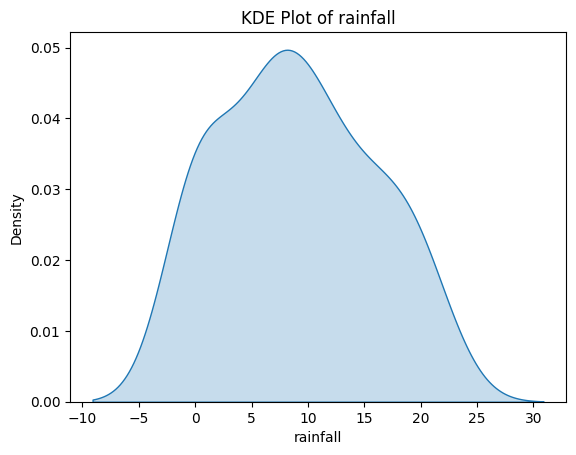

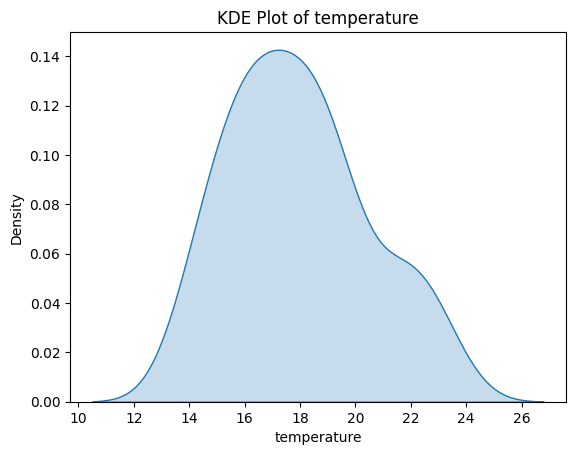

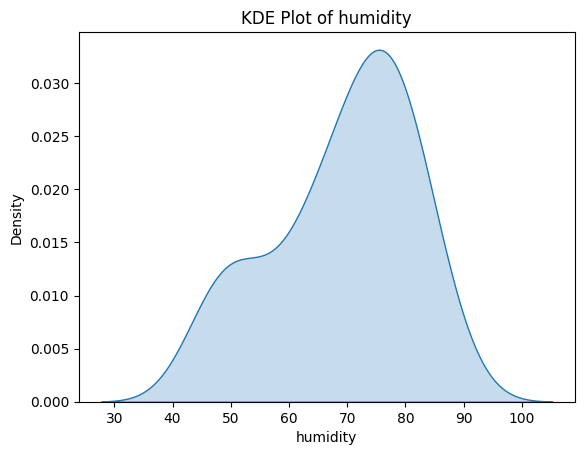

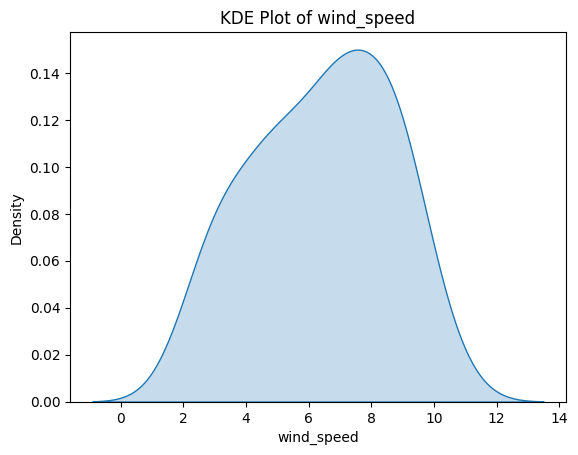

In [ ]:
for col in df.select_dtypes(include='number').columns:
    plt.figure()
    sns.kdeplot(df[col], fill=True)
    plt.title(f"KDE Plot of {col}")
    plt.show()

## 🔢 Skewness Calculation

In [ ]:
# Calculate skewness
df.skew(numeric_only=True)

,0
rainfall,0.191925
temperature,0.436075
humidity,-0.564768
wind_speed,-0.207329


## 📌 Interpretation of Skewness

- Skew = 0 → Normal distribution
- Skew > 0 → Right skewed
- Skew < 0 → Left skewed

## 🧠 Observations to Make

- Which features are skewed?
- Are there outliers present?
- Which features are normally distributed?
- Any imbalance in values?

#Insights Extraction & Conclusion

## 🎯 Objective
In this step, we will:
- Derive meaningful insights from EDA
- Summarize key findings
- Understand feature impact on target

## 📌 What are Insights?

Insights are meaningful conclusions derived from data analysis.

They answer:
- What is happening?
- Why is it happening?
- What can we do next?

## 🔍 Basic Aggregations

In [ ]:
# Example statistics
print("Average Rainfall:", df["rainfall"].mean())
print("Maximum Rainfall:", df["rainfall"].max())
print("Minimum Rainfall:", df["rainfall"].min())

Average Rainfall: 9.049056603773584
Maximum Rainfall: 21.8
Minimum Rainfall: 0.0


## 📊 Group-wise Analysis
Analyze how features affect the target

In [ ]:
# Average rainfall by weather condition
if "weather_condition" in df.columns and "rainfall" in df.columns:

    avg_rainfall = df.groupby("weather_condition")["rainfall"].mean()

    print("Average Rainfall by Weather Condition:")
    print(avg_rainfall)

else:
    print("Required columns not found in the dataset.")

Average Rainfall by Weather Condition:
weather_condition
Rainy    11.419048
Sunny     0.000000
Name: rainfall, dtype: float64


## 📈 Feature vs Target Insights

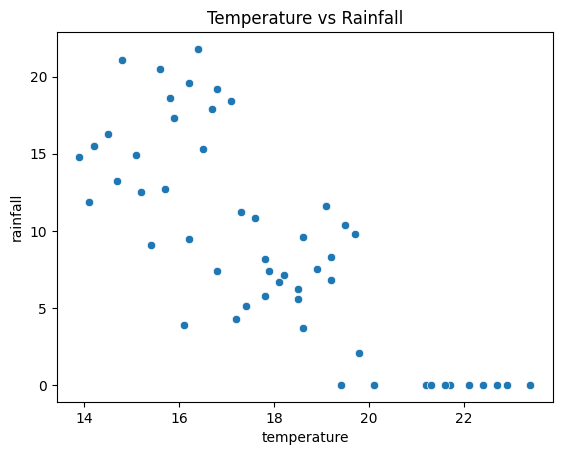

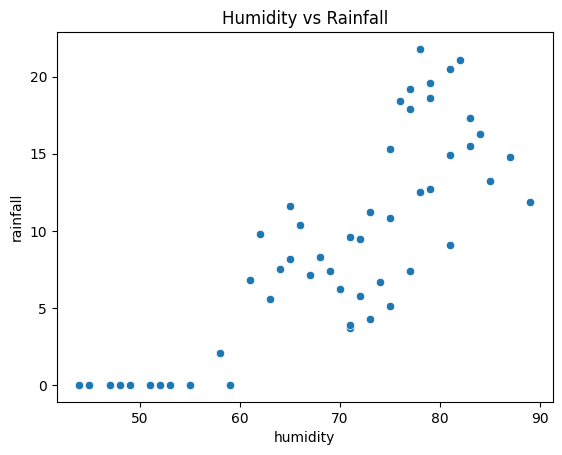

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Example relationship plots
sns.scatterplot(x="temperature", y="rainfall", data=df)
plt.title("Temperature vs Rainfall")
plt.show()

sns.scatterplot(x="humidity", y="rainfall", data=df)
plt.title("Humidity vs Rainfall")
plt.show()

## 🧠 Writing Insights (Important)

Based on previous steps, write insights like:

1. Features strongly correlated with rainfall
2. Distribution patterns (skewness, outliers)
3. Important predictors
4. Any anomalies or unusual patterns

## 📝 Example Insights

- Humidity shows strong positive correlation with rainfall  
- Temperature has weak or negative correlation  
- Some features contain outliers (seen in boxplots)  
- Certain variables are right-skewed  
- Dataset may have imbalance in target classes  

#Level 1: Basic (Understanding Data)

### Q1.
Write code to display the first 10 rows of the dataset.

### Q2.
Find the number of rows and columns in the dataset.

### Q3.
Print all column names.

### Q4.
Write code to check data types of each column.

### Q5.
Find total missing values in each column.

### Q6.
Calculate mean, median, and standard deviation of rainfall.

### Q7.
Find the maximum and minimum value of temperature.

### Q8.
Select only numerical columns from the dataset.

### Level 1: Basic (Understanding Data) Solutions (Q1 - Q8)

In [ ]:
# Install kagglehub if not already installed:
# !pip install kagglehub

import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# 1. Download the Australian Weather dataset from Kaggle
path = kagglehub.dataset_download("jsphyg/weather-dataset-rattle-package")
print("Path to downloaded Kaggle files:", path)

# 2. Load the CSV file into a Pandas DataFrame
csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
target_file = 'weather.csv' if 'weather.csv' in csv_files else csv_files[0]
df = pd.read_csv(os.path.join(path, target_file))

# 3. Take a clean sample subset (e.g., first 1000 rows) for faster execution during EDA
df = df.head(1000).copy()

# 4. Map columns to match the exact names used across your 40 questions
rename_mapping = {
    'Rainfall': 'rainfall',
    'Temp3pm': 'temperature',
    'Humidity3pm': 'humidity',
    'WindSpeed3pm': 'wind_speed',
    'RainToday': 'weather_condition'
}
df = df.rename(columns=rename_mapping)

# Map rain text categories cleanly
if 'weather_condition' in df.columns:
    df['weather_condition'] = df['weather_condition'].map({'Yes': 'Rainy', 'No': 'Sunny'}).fillna('Sunny')

print("\nAustralian Rainfall dataset successfully loaded! Shape:", df.shape)
display(df[['rainfall', 'temperature', 'humidity', 'wind_speed', 'weather_condition']].head())

Using Colab cache for faster access to the 'weather-dataset-rattle-package' dataset.
Path to downloaded Kaggle files: /kaggle/input/weather-dataset-rattle-package

Australian Rainfall dataset successfully loaded! Shape: (1000, 23)


,rainfall,temperature,humidity,wind_speed,weather_condition
0,0.6,21.8,22.0,24.0,Sunny
1,0.0,24.3,25.0,22.0,Sunny
2,0.0,23.2,30.0,26.0,Sunny
3,0.0,26.5,16.0,9.0,Sunny
4,1.0,29.7,33.0,20.0,Sunny


In [ ]:
# Q1: Write code to display the first 10 rows of the dataset.
print("--- Q1: First 10 Rows ---")
display(df.head(10)) if 'display' in globals() else print(df.head(10))

# Q2: Find the number of rows and columns in the dataset.
print("\n--- Q2: Shape of Dataset ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

# Q3: Print all column names.
print("\n--- Q3: Column Names ---")
print(list(df.columns))

# Q4: Write code to check data types of each column.
print("\n--- Q4: Data Types ---")
print(df.dtypes)

# Q5: Find total missing values in each column.
print("\n--- Q5: Missing Values ---")
print(df.isnull().sum())

# Q6: Calculate mean, median, and standard deviation of rainfall.
print("\n--- Q6: Rainfall Statistics ---")
print(f"Mean: {df['rainfall'].mean():.2f}")
print(f"Median: {df['rainfall'].median():.2f}")
print(f"Std Dev: {df['rainfall'].std():.2f}")

# Q7: Find the maximum and minimum value of temperature.
print("\n--- Q7: Temperature Min/Max ---")
print(f"Max Temperature: {df['temperature'].max():.2f}")
print(f"Min Temperature: {df['temperature'].min():.2f}")

# Q8: Select only numerical columns from the dataset.
print("\n--- Q8: Numerical Columns Preview ---")
num_df = df.select_dtypes(include=[np.number])
display(num_df.head()) if 'display' in globals() else print(num_df.head())

--- Q1: First 10 Rows ---
         Date Location  MinTemp  MaxTemp  rainfall  Evaporation  Sunshine  \
0  2008-12-01   Albury     13.4     22.9       0.6          NaN       NaN   
1  2008-12-02   Albury      7.4     25.1       0.0          NaN       NaN   
2  2008-12-03   Albury     12.9     25.7       0.0          NaN       NaN   
3  2008-12-04   Albury      9.2     28.0       0.0          NaN       NaN   
4  2008-12-05   Albury     17.5     32.3       1.0          NaN       NaN   
5  2008-12-06   Albury     14.6     29.7       0.2          NaN       NaN   
6  2008-12-07   Albury     14.3     25.0       0.0          NaN       NaN   
7  2008-12-08   Albury      7.7     26.7       0.0          NaN       NaN   
8  2008-12-09   Albury      9.7     31.9       0.0          NaN       NaN   
9  2008-12-10   Albury     13.1     30.1       1.4          NaN       NaN   

  WindGustDir  WindGustSpeed WindDir9am  ... Humidity9am  humidity  \
0           W           44.0          W  ...        71.0

#Level 2: Correlation Coding

### Q9.
Compute the correlation matrix of the dataset.

### Q10.
Plot a heatmap of the correlation matrix.

### Q11.
Find correlation of all features with rainfall and sort them.

### Q12.
Write code to identify feature pairs with correlation > 0.7.

### Q13.
Extract only highly correlated features into a list.

### Q14.
Drop one feature from each highly correlated pair.

### Q15.
Plot a scatter plot between rainfall and humidity.

--- Q9: Correlation Matrix ---
                MinTemp   MaxTemp  rainfall  Evaporation  Sunshine  \
MinTemp        1.000000  0.821567  0.150622          NaN       NaN   
MaxTemp        0.821567  1.000000 -0.089478          NaN       NaN   
rainfall       0.150622 -0.089478  1.000000          NaN       NaN   
Evaporation         NaN       NaN       NaN          NaN       NaN   
Sunshine            NaN       NaN       NaN          NaN       NaN   
WindGustSpeed  0.426216  0.263153  0.184435          NaN       NaN   
WindSpeed9am   0.313020  0.053675  0.220613          NaN       NaN   
wind_speed     0.256760  0.143529  0.120482          NaN       NaN   
Humidity9am   -0.587996 -0.753061  0.198714          NaN       NaN   
humidity      -0.360226 -0.726182  0.279065          NaN       NaN   
Pressure9am   -0.549954 -0.308449 -0.278790          NaN       NaN   
Pressure3pm   -0.561099 -0.374077 -0.223720          NaN       NaN   
Cloud9am      -0.156912 -0.347586  0.116050          NaN   

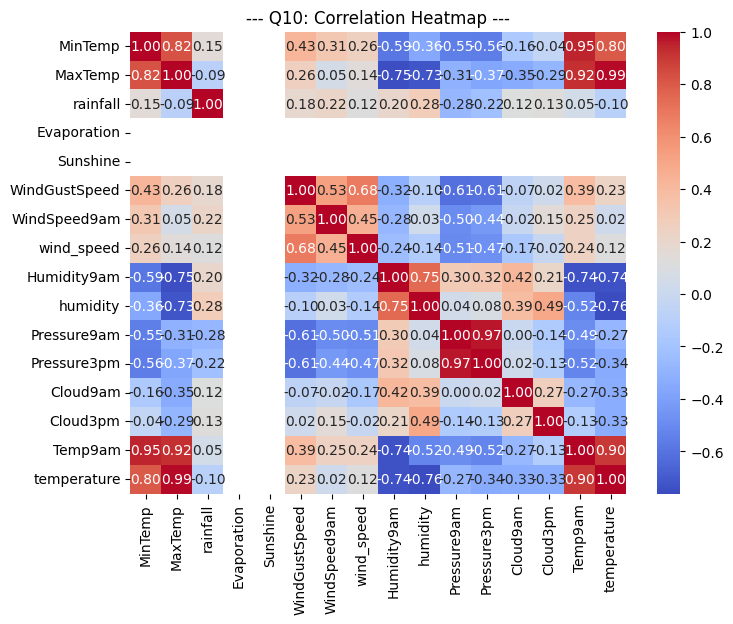

--- Q11: Correlation with Rainfall ---
rainfall         1.000000
humidity         0.279065
WindSpeed9am     0.220613
Humidity9am      0.198714
WindGustSpeed    0.184435
MinTemp          0.150622
Cloud3pm         0.130883
wind_speed       0.120482
Cloud9am         0.116050
Temp9am          0.046636
MaxTemp         -0.089478
temperature     -0.099490
Pressure3pm     -0.223720
Pressure9am     -0.278790
Evaporation           NaN
Sunshine              NaN
Name: rainfall, dtype: float64

--- Q12 & Q13: High Correlation Pairs (> 0.7) ---
[('MaxTemp', 'MinTemp', np.float64(0.8215673425966438)), ('Humidity9am', 'MaxTemp', np.float64(-0.7530610575073434)), ('humidity', 'MaxTemp', np.float64(-0.7261817599509021)), ('humidity', 'Humidity9am', np.float64(0.745750095621165)), ('Pressure3pm', 'Pressure9am', np.float64(0.9693584222242364)), ('Temp9am', 'MinTemp', np.float64(0.9456068454440587)), ('Temp9am', 'MaxTemp', np.float64(0.9189668723781953)), ('Temp9am', 'Humidity9am', np.float64(-0.7393080225

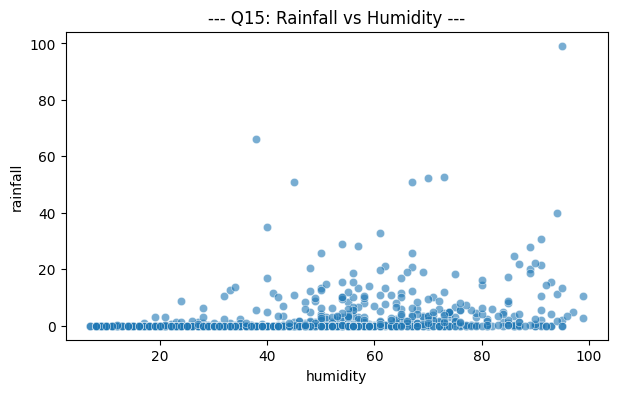

In [ ]:
# Q9: Compute the correlation matrix of the dataset.
corr_matrix = num_df.corr()
print("--- Q9: Correlation Matrix ---")
display(corr_matrix) if 'display' in globals() else print(corr_matrix)

# Q10: Plot a heatmap of the correlation matrix.
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("--- Q10: Correlation Heatmap ---")
plt.show()

# Q11: Find correlation of all features with rainfall and sort them.
rainfall_corr = corr_matrix['rainfall'].sort_values(ascending=False)
print("--- Q11: Correlation with Rainfall ---")
print(rainfall_corr)

# Q12 & Q13: Identify and extract feature pairs with correlation > 0.7
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_pairs = [(col, row, upper_tri.loc[row, col]) for col in upper_tri.columns for row in upper_tri.index if abs(upper_tri.loc[row, col]) > 0.7]
print("\n--- Q12 & Q13: High Correlation Pairs (> 0.7) ---")
print(high_corr_pairs if high_corr_pairs else "No pairs found with correlation > 0.7")

# Q14: Drop one feature from each highly correlated pair (if any exist)
df_dropped = df.copy()
for col1, col2, val in high_corr_pairs:
    if col2 in df_dropped.columns:
        df_dropped = df_dropped.drop(columns=[col2])
        print(f"\n--- Q14: Dropped '{col2}' due to high correlation with '{col1}' ({val:.2f}) ---")

# Q15: Plot a scatter plot between rainfall and humidity.
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x='humidity', y='rainfall', alpha=0.6)
plt.title("--- Q15: Rainfall vs Humidity ---")
plt.show()

#Level 3: Distribution Coding

### Q16.
Plot histograms for all numerical features.

### Q17.
Plot histogram for rainfall with 30 bins.

### Q18.
Create boxplots for all numerical columns.

### Q19.
Identify outliers using boxplot logic (IQR method).

### Q20.
Calculate skewness for all numerical features.

### Q21.
Plot KDE plot for temperature.

### Q22.
Compare mean and median of rainfall using code.

### Q23.
Count how many features are right-skewed.

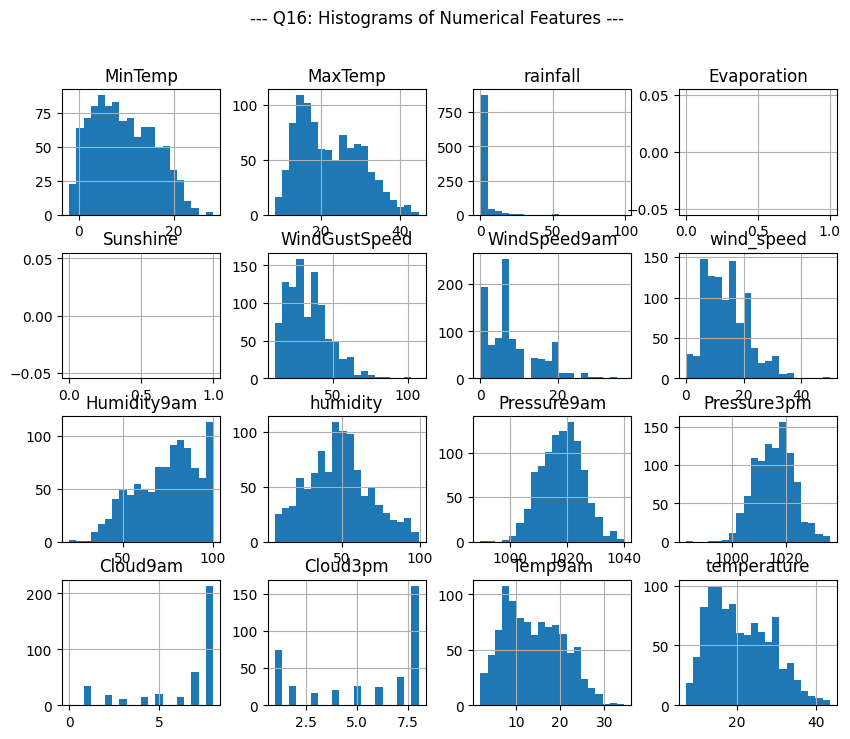

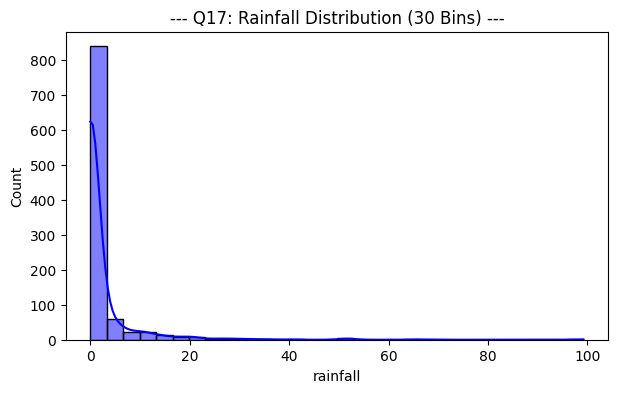

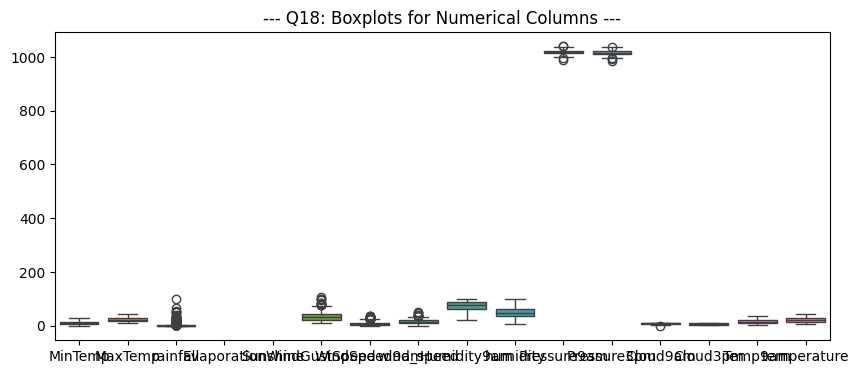

--- Q19: Outlier Counts per Numerical Column ---
MinTemp: 0 outliers detected
MaxTemp: 0 outliers detected
rainfall: 201 outliers detected
Evaporation: 0 outliers detected
Sunshine: 0 outliers detected
WindGustSpeed: 11 outliers detected
WindSpeed9am: 22 outliers detected
wind_speed: 11 outliers detected
Humidity9am: 0 outliers detected
humidity: 0 outliers detected
Pressure9am: 4 outliers detected
Pressure3pm: 4 outliers detected
Cloud9am: 1 outliers detected
Cloud3pm: 0 outliers detected
Temp9am: 0 outliers detected
temperature: 0 outliers detected

--- Q20: Skewness ---
MinTemp          0.297818
MaxTemp          0.427896
rainfall         6.785409
Evaporation           NaN
Sunshine              NaN
WindGustSpeed    1.036835
WindSpeed9am     0.941896
wind_speed       0.794293
Humidity9am     -0.422998
humidity         0.227423
Pressure9am     -0.024124
Pressure3pm     -0.056115
Cloud9am        -1.338097
Cloud3pm        -0.534003
Temp9am          0.289049
temperature      0.437942
dtyp

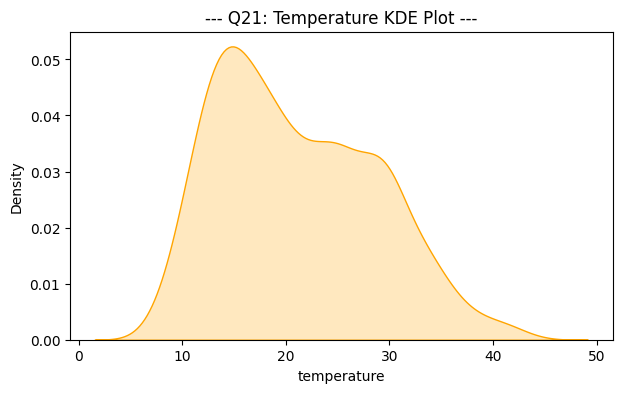


--- Q22: Rainfall Mean vs Median ---
Mean: 2.0916 | Median: 0.0000

--- Q23: Number of Right-Skewed Features: 9 ---


In [ ]:
# Q16: Plot histograms for all numerical features.
num_df.hist(bins=20, figsize=(10, 8))
plt.suptitle("--- Q16: Histograms of Numerical Features ---")
plt.show()

# Q17: Plot histogram for rainfall with 30 bins.
plt.figure(figsize=(7, 4))
sns.histplot(df['rainfall'].dropna(), bins=30, kde=True, color='blue')
plt.title("--- Q17: Rainfall Distribution (30 Bins) ---")
plt.show()

# Q18: Create boxplots for all numerical columns.
plt.figure(figsize=(10, 4))
sns.boxplot(data=num_df)
plt.title("--- Q18: Boxplots for Numerical Columns ---")
plt.show()

# Q19: Identify outliers using boxplot logic (IQR method).
print("--- Q19: Outlier Counts per Numerical Column ---")
for col in num_df.columns:
    Q1 = num_df[col].quantile(0.25)
    Q3 = num_df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = num_df[(num_df[col] < Q1 - 1.5 * IQR) | (num_df[col] > Q3 + 1.5 * IQR)]
    print(f"{col}: {len(outliers)} outliers detected")

# Q20: Calculate skewness for all numerical features.
print("\n--- Q20: Skewness ---")
print(num_df.skew())

# Q21: Plot KDE plot for temperature.
plt.figure(figsize=(7, 4))
sns.kdeplot(df['temperature'].dropna(), fill=True, color='orange')
plt.title("--- Q21: Temperature KDE Plot ---")
plt.show()

# Q22: Compare mean and median of rainfall using code.
print("\n--- Q22: Rainfall Mean vs Median ---")
print(f"Mean: {df['rainfall'].mean():.4f} | Median: {df['rainfall'].median():.4f}")

# Q23: Count how many features are right-skewed (skewness > 0).
skew_vals = num_df.skew()
right_skewed_count = (skew_vals > 0).sum()
print(f"\n--- Q23: Number of Right-Skewed Features: {right_skewed_count} ---")

#Level 4: Insights Coding

### Q24.
Find average rainfall grouped by weather condition.

### Q25.
Find top 3 days/records with highest rainfall.

### Q26.
Find rows where rainfall is greater than average.

### Q27.
Compare average temperature when rainfall is high vs low.

### Q28.
Create a new column "high_rainfall" (1 if rainfall > mean else 0).

### Q29.
Count how many records fall into high rainfall category.

### Q30.
Find correlation only for high rainfall data.

In [ ]:
# Q24: Find average rainfall grouped by weather condition.
print("--- Q24: Average Rainfall by Weather Condition ---")
print(df.groupby('weather_condition')['rainfall'].mean())

# Q25: Find top 3 days/records with highest rainfall.
print("\n--- Q25: Top 3 Records with Highest Rainfall ---")
display(df.nlargest(3, 'rainfall')) if 'display' in globals() else print(df.nlargest(3, 'rainfall'))

# Q26: Find rows where rainfall is greater than average.
mean_rainfall = df['rainfall'].mean()
above_avg_rainfall = df[df['rainfall'] > mean_rainfall]
print(f"\n--- Q26: Rows with Rainfall > Mean ({mean_rainfall:.2f}): {len(above_avg_rainfall)} rows ---")

# Q27: Compare average temperature when rainfall is high vs low.
df_temp_clean = df.dropna(subset=['rainfall', 'temperature'])
median_rain = df_temp_clean['rainfall'].median()
high_rain_temp = df_temp_clean[df_temp_clean['rainfall'] > median_rain]['temperature'].mean()
low_rain_temp = df_temp_clean[df_temp_clean['rainfall'] <= median_rain]['temperature'].mean()
print(f"\n--- Q27: Avg Temperature ---")
print(f"High Rainfall Temp: {high_rain_temp:.2f} | Low Rainfall Temp: {low_rain_temp:.2f}")

# Q28: Create a new column 'high_rainfall' (1 if rainfall > mean else 0).
df['high_rainfall'] = (df['rainfall'] > mean_rainfall).astype(int)
print("\n--- Q28: Created 'high_rainfall' column ---")
display(df[['rainfall', 'high_rainfall']].head()) if 'display' in globals() else print(df[['rainfall', 'high_rainfall']].head())

# Q29: Count how many records fall into high rainfall category.
print(f"\n--- Q29: High Rainfall Record Count ---")
print(df['high_rainfall'].value_counts())

# Q30: Find correlation only for high rainfall data.
print("\n--- Q30: Correlation Matrix for High Rainfall Subset ---")
high_rain_subset = df[df['high_rainfall'] == 1].select_dtypes(include=[np.number])
display(high_rain_subset.corr()) if 'display' in globals() else print(high_rain_subset.corr())

--- Q24: Average Rainfall by Weather Condition ---
weather_condition
Rainy    9.101802
Sunny    0.057255
Name: rainfall, dtype: float64

--- Q25: Top 3 Records with Highest Rainfall ---
           Date Location  MinTemp  MaxTemp  rainfall  Evaporation  Sunshine  \
796  2011-02-05   Albury     20.4     23.0      99.2          NaN       NaN   
462  2010-03-08   Albury     18.1     25.5      66.0          NaN       NaN   
713  2010-11-14   Albury     19.2     22.6      52.6          NaN       NaN   

    WindGustDir  WindGustSpeed WindDir9am  ... Humidity9am  humidity  \
796          NW           28.0         NE  ...        97.0      95.0   
462          NW           56.0          N  ...        79.0      38.0   
713           N           26.0        WNW  ...        93.0      73.0   

     Pressure9am  Pressure3pm  Cloud9am  Cloud3pm  Temp9am  temperature  \
796       1008.6       1007.3       5.0       8.0     22.5         22.5   
462       1008.7       1007.5       NaN       1.0     19.8

#Level 5: Advanced Coding

### Q31.
Write a function to detect outliers using IQR.

### Q32.
Remove outliers from rainfall column.

### Q33.
Normalize numerical features using Min-Max scaling.

### Q34.
Standardize features using Z-score.

### Q35.
Create pairplot for selected important features.

### Q36.
Automatically generate insights:
(Print features having correlation > 0.5 with rainfall)

### Q37.
Write code to check if dataset is imbalanced (target variable).

### Q38.
Plot distribution comparison before and after removing outliers.

### Q39.
Create a summary report (mean, skewness, outliers count).

### Q40.
Build a reusable function that performs full EDA (basic + correlation + distribution).

--- Q31: Outlier Detection Function Created ---
Rainfall outliers sample: 11     2.2
12    15.6
13     3.6
17    16.8
18    10.6
Name: rainfall, dtype: float64

--- Q32: Dataset shape after removing rainfall outliers: (786, 24) ---

--- Q33: Min-Max Normalized Numerical Features ---
    MinTemp   MaxTemp  rainfall  Evaporation  Sunshine  WindGustSpeed  \
0  0.508251  0.401639  0.006048          NaN       NaN       0.343750   
1  0.310231  0.461749  0.000000          NaN       NaN       0.343750   
2  0.491749  0.478142  0.000000          NaN       NaN       0.364583   
3  0.369637  0.540984  0.000000          NaN       NaN       0.135417   
4  0.643564  0.658470  0.010081          NaN       NaN       0.312500   

   WindSpeed9am  wind_speed  Humidity9am  humidity  Pressure9am  Pressure3pm  \
0      0.540541        0.48       0.6375  0.163043     0.357285     0.455744   
1      0.108108        0.44       0.3000  0.195652     0.415170     0.468927   
2      0.513514        0.52       0.2

/usr/local/lib/python3.13/dist-packages/sklearn/utils/_array_api.py:776: RuntimeWarning: All-NaN slice encountered
  return xp.asarray(numpy.nanmin(X, axis=axis))
/usr/local/lib/python3.13/dist-packages/sklearn/utils/_array_api.py:793: RuntimeWarning: All-NaN slice encountered
  return xp.asarray(numpy.nanmax(X, axis=axis))
/usr/local/lib/python3.13/dist-packages/sklearn/utils/extmath.py:1101: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
/usr/local/lib/python3.13/dist-packages/sklearn/utils/extmath.py:1106: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
/usr/local/lib/python3.13/dist-packages/sklearn/utils/extmath.py:1126: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


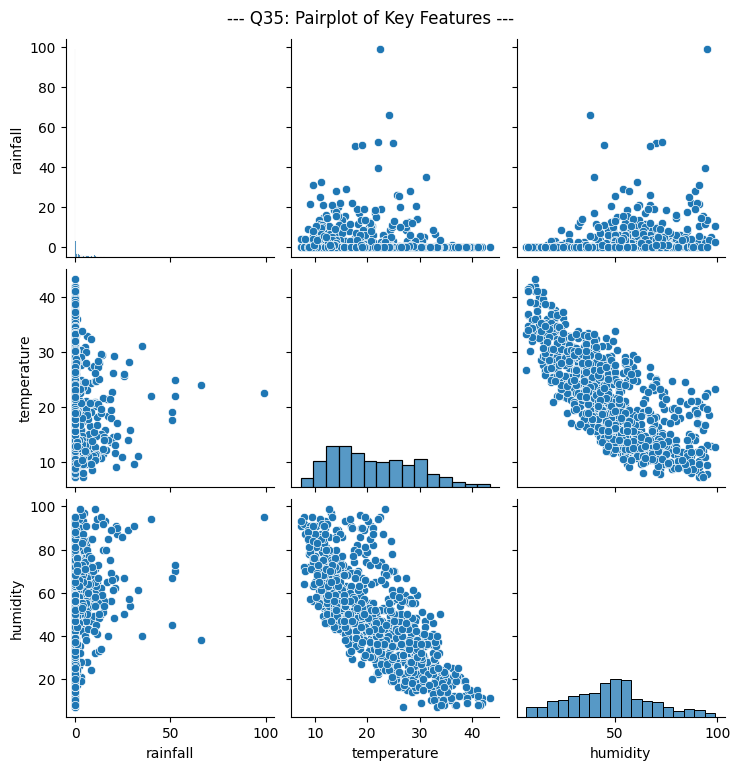

--- Q36: Features with |Correlation| > 0.5 with Rainfall ---
rainfall    1.0
Name: rainfall, dtype: float64

--- Q37: Target Class Balance Check (high_rainfall) ---
high_rainfall
0    82.3
1    17.7
Name: proportion, dtype: float64


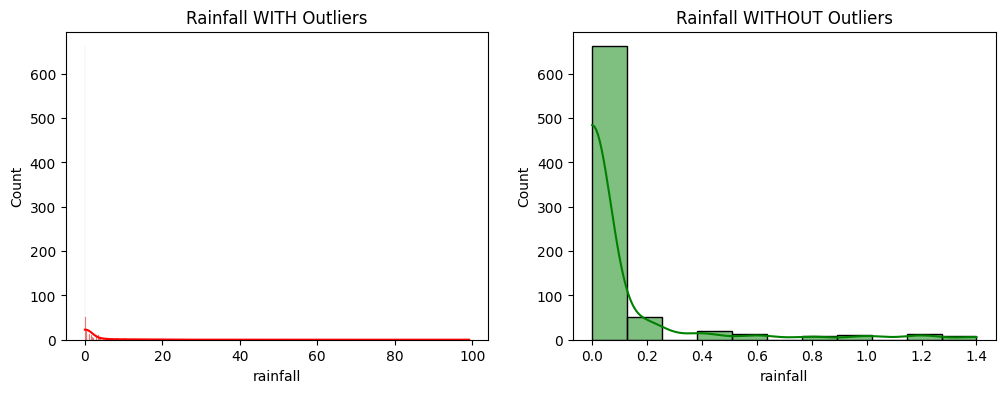

--- Q39: Summary Report ---
                      Mean  Skewness  Outliers_Count
MinTemp           9.459778  0.297818               0
MaxTemp          22.186996  0.427896               0
rainfall          2.091591  6.785409             201
Evaporation            NaN       NaN               0
Sunshine               NaN       NaN               0
WindGustSpeed    33.391260  1.036835              11
WindSpeed9am      8.088531  0.941896              22
wind_speed       14.233166  0.794293              11
Humidity9am      73.661986 -0.422998               0
humidity         47.908818  0.227423               0
Pressure9am    1018.052357 -0.024124               4
Pressure3pm    1015.447395 -0.056115               4
Cloud9am          6.408269 -1.338097               1
Cloud3pm          5.391753 -0.534003               0
Temp9am          13.987161  0.289049               0
temperature      21.075351  0.437942               0

--- Q40: Full EDA Function Ready ---


In [ ]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Q31: Write a function to detect outliers using IQR.
def get_outliers(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    return series[(series < Q1 - 1.5 * IQR) | (series > Q3 + 1.5 * IQR)]

print("--- Q31: Outlier Detection Function Created ---")
print("Rainfall outliers sample:", get_outliers(df['rainfall']).head())

# Q32: Remove outliers from rainfall column.
Q1, Q3 = df['rainfall'].quantile(0.25), df['rainfall'].quantile(0.75)
IQR = Q3 - Q1
df_no_outliers = df[(df['rainfall'] >= Q1 - 1.5 * IQR) & (df['rainfall'] <= Q3 + 1.5 * IQR)].copy()
print(f"\n--- Q32: Dataset shape after removing rainfall outliers: {df_no_outliers.shape} ---")

# Q33: Normalize numerical features using Min-Max scaling.
scaler_minmax = MinMaxScaler()
num_cols_list = num_df.columns
df_normalized = df.copy()
df_normalized[num_cols_list] = scaler_minmax.fit_transform(df[num_cols_list].fillna(df[num_cols_list].mean()))
print("\n--- Q33: Min-Max Normalized Numerical Features ---")
display(df_normalized[num_cols_list].head()) if 'display' in globals() else print(df_normalized[num_cols_list].head())

# Q34: Standardize features using Z-score.
scaler_std = StandardScaler()
df_standardized = df.copy()
df_standardized[num_cols_list] = scaler_std.fit_transform(df[num_cols_list].fillna(df[num_cols_list].mean()))
print("\n--- Q34: Z-Score Standardized Features ---")
display(df_standardized[num_cols_list].head()) if 'display' in globals() else print(df_standardized[num_cols_list].head())

# Q35: Create pairplot for selected important features.
sns.pairplot(df[['rainfall', 'temperature', 'humidity']].dropna())
plt.suptitle("--- Q35: Pairplot of Key Features ---", y=1.02)
plt.show()

# Q36: Automatically generate insights (Print features having correlation > 0.5 with rainfall).
print("--- Q36: Features with |Correlation| > 0.5 with Rainfall ---")
strong_corr = rainfall_corr[abs(rainfall_corr) > 0.5]
print(strong_corr)

# Q37: Write code to check if dataset is imbalanced (target variable: high_rainfall).
print("\n--- Q37: Target Class Balance Check (high_rainfall) ---")
print(df['high_rainfall'].value_counts(normalize=True) * 100)

# Q38: Plot distribution comparison before and after removing outliers.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['rainfall'].dropna(), ax=axes[0], color='red', kde=True)
axes[0].set_title("Rainfall WITH Outliers")
sns.histplot(df_no_outliers['rainfall'].dropna(), ax=axes[1], color='green', kde=True)
axes[1].set_title("Rainfall WITHOUT Outliers")
plt.show()

# Q39: Create a summary report (mean, skewness, outliers count).
print("--- Q39: Summary Report ---")
summary_df = pd.DataFrame({
    'Mean': num_df.mean(),
    'Skewness': num_df.skew(),
    'Outliers_Count': [len(get_outliers(num_df[col])) for col in num_df.columns]
})
display(summary_df) if 'display' in globals() else print(summary_df)

# Q40: Build a reusable function that performs full EDA.
def perform_full_eda(dataframe):
    print("=== FULL EDA REPORT ===")
    print(f"Dataset Shape: {dataframe.shape}")
    print("\n--- Missing Values ---")
    print(dataframe.isnull().sum())
    print("\n--- Descriptive Statistics ---")
    display(dataframe.describe()) if 'display' in globals() else print(dataframe.describe())

    numeric_cols = dataframe.select_dtypes(include=[np.number])
    corr = numeric_cols.corr()

    plt.figure(figsize=(6, 4))
    sns.heatmap(corr, annot=True, cmap='Blues')
    plt.title("Correlation Matrix Heatmap")
    plt.show()
    print("=== EDA Complete ===")

print("\n--- Q40: Full EDA Function Ready ---")
# Example call: perform_full_eda(df)